**Actividad Formativa 3: Implementación y evaluación de filtros digitales
Objetivo**

Diseñar, implementar y evaluar tres filtros digitales: pasa bajos, pasa altos y pasa bandas, utilizando Python y Google Colab, con el propósito de analizar su comportamiento y efectividad en señales que contienen diferentes frecuencias y ruido.
Herramientas utilizadas

    Python: lenguaje de programación utilizado para desarrollar la simulación.

    Google Colab: entorno de ejecución del código.

    NumPy: biblioteca utilizada para generar y procesar señales.

    SciPy: biblioteca utilizada para diseñar y aplicar filtros digitales Butterworth.

    Matplotlib: biblioteca utilizada para generar gráficas y visualizar resultados.

Metodología

Se generó una señal digital compuesta por tres frecuencias: 5 Hz, 50 Hz y 120 Hz, a la que se agregó ruido aleatorio.

Posteriormente, se diseñaron tres filtros digitales Butterworth:

    Filtro pasa bajos con frecuencia de corte de 20 Hz.

    Filtro pasa altos con frecuencia de corte de 80 Hz.

    Filtro pasa bandas con frecuencias de corte de 40 Hz y 60 Hz.

Los filtros se aplicaron a la señal original para comparar sus resultados en el dominio del tiempo y analizar su respuesta en frecuencia.
Resultados

Los resultados mostraron que cada filtro permitió conservar principalmente las frecuencias deseadas y atenuar aquellas que se encontraban fuera de su región de paso.

El filtro pasa bajos conservó principalmente la componente de 5 Hz; el filtro pasa altos conservó la componente de 120 Hz; y el filtro pasa bandas permitió aislar principalmente la frecuencia de 50 Hz.
Conclusión

La implementación de filtros digitales permitió comprender cómo es posible modificar una señal mediante el procesamiento de sus componentes de frecuencia.

Las simulaciones demostraron que los filtros Butterworth son herramientas útiles para seleccionar determinadas frecuencias y atenuar otras. Su efectividad depende del tipo de filtro, las frecuencias de corte y las características de la señal original.

Esta actividad permitió aplicar conocimientos de procesamiento digital de señales mediante programación en Python y análisis gráfico de resultados.

In [1]:

# Actividad Formativa 3
# Implementacion y evaluacion de filtros digitales

# Importar bibliotecas necesarias
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, sosfreqz

print("Bibliotecas cargadas correctamente")
print("Listo para comenzar la actividad")


Bibliotecas cargadas correctamente
Listo para comenzar la actividad


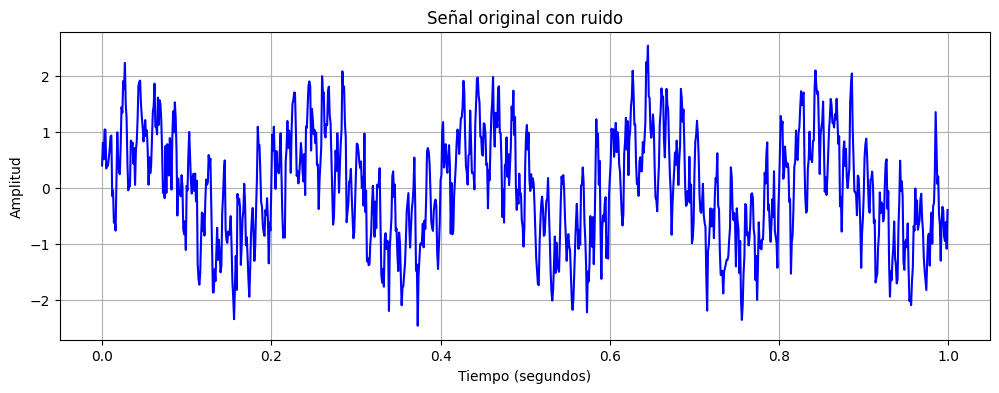

In [2]:

# PASO 4: CREAR UNA SEÑAL DIGITAL CON RUIDO

# Frecuencia de muestreo: 1000 muestras por segundo
fs = 1000

# Tiempo de duracion: 1 segundo
t = np.arange(0, 1, 1/fs)

# Crear tres señales con distintas frecuencias
senal_5 = np.sin(2 * np.pi * 5 * t)
senal_50 = 0.7 * np.sin(2 * np.pi * 50 * t)
senal_120 = 0.5 * np.sin(2 * np.pi * 120 * t)

# Generar ruido aleatorio
np.random.seed(10)
ruido = 0.3 * np.random.randn(len(t))

# Combinar las señales y el ruido
senal = senal_5 + senal_50 + senal_120 + ruido

# Graficar la señal original
plt.figure(figsize=(12, 4))
plt.plot(t, senal, color="blue")

plt.title("Señal original con ruido")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.grid(True)

plt.show()


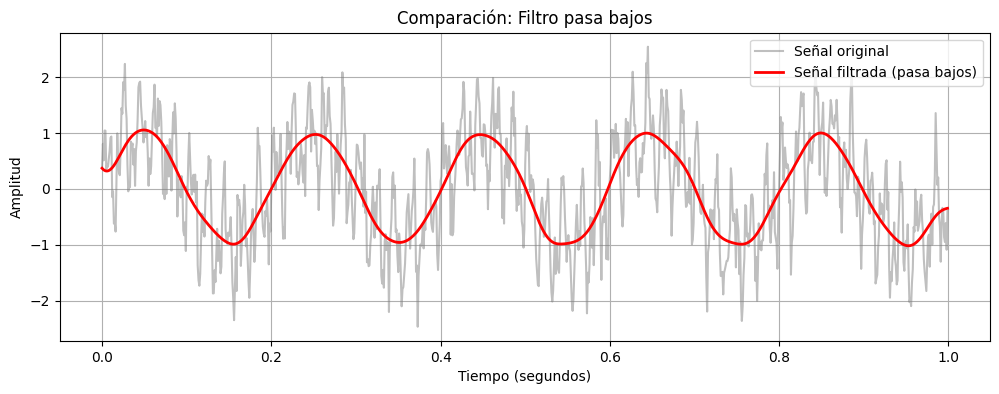

In [3]:

# PASO 5: IMPLEMENTAR FILTRO PASA BAJOS

# Diseñar filtro Butterworth de orden 4
# Frecuencia de corte: 20 Hz
sos_bajos = butter(
    4, 20, btype="low",
    fs=fs, output="sos"
)

# Aplicar el filtro a la señal original
filtrada_bajos = sosfiltfilt(sos_bajos, senal)

# Comparar la señal original y la filtrada
plt.figure(figsize=(12, 4))

plt.plot(t, senal, label="Señal original",
         color="gray", alpha=0.5)

plt.plot(t, filtrada_bajos,
         label="Señal filtrada (pasa bajos)",
         color="red", linewidth=2)

plt.title("Comparación: Filtro pasa bajos")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid(True)

plt.savefig("02_Filtro_Pasa_Bajos.png", dpi=300)
plt.show()


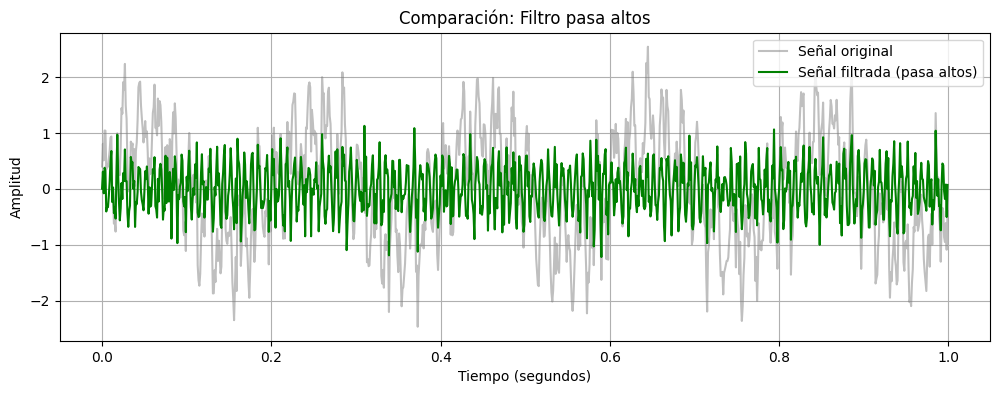

In [4]:

# PASO 6: IMPLEMENTAR FILTRO PASA ALTOS

# Diseñar filtro Butterworth de orden 4
# Frecuencia de corte: 80 Hz
sos_altos = butter(
    4, 80, btype="high",
    fs=fs, output="sos"
)

# Aplicar el filtro a la señal original
filtrada_altos = sosfiltfilt(sos_altos, senal)

# Comparar la señal original y la filtrada
plt.figure(figsize=(12, 4))

plt.plot(t, senal, label="Señal original",
         color="gray", alpha=0.5)

plt.plot(t, filtrada_altos,
         label="Señal filtrada (pasa altos)",
         color="green", linewidth=1.5)

plt.title("Comparación: Filtro pasa altos")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid(True)

# Guardar la gráfica
plt.savefig("03_Filtro_Pasa_Altos.png", dpi=300)

plt.show()


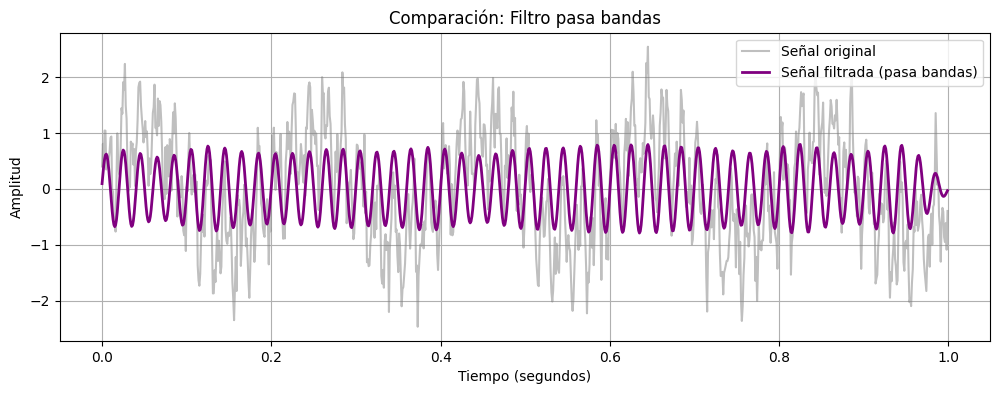

In [5]:

# PASO 7: IMPLEMENTAR FILTRO PASA BANDAS

# Diseñar filtro Butterworth de orden 4
# Banda de paso: 40 Hz a 60 Hz
sos_bandas = butter(
    4, [40, 60], btype="bandpass",
    fs=fs, output="sos"
)

# Aplicar el filtro a la señal original
filtrada_bandas = sosfiltfilt(sos_bandas, senal)

# Comparar la señal original y la filtrada
plt.figure(figsize=(12, 4))

plt.plot(t, senal,
         label="Señal original",
         color="gray", alpha=0.5)

plt.plot(t, filtrada_bandas,
         label="Señal filtrada (pasa bandas)",
         color="purple", linewidth=2)

plt.title("Comparación: Filtro pasa bandas")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid(True)

# Guardar la gráfica
plt.savefig("04_Filtro_Pasa_Bandas.png", dpi=300)

plt.show()


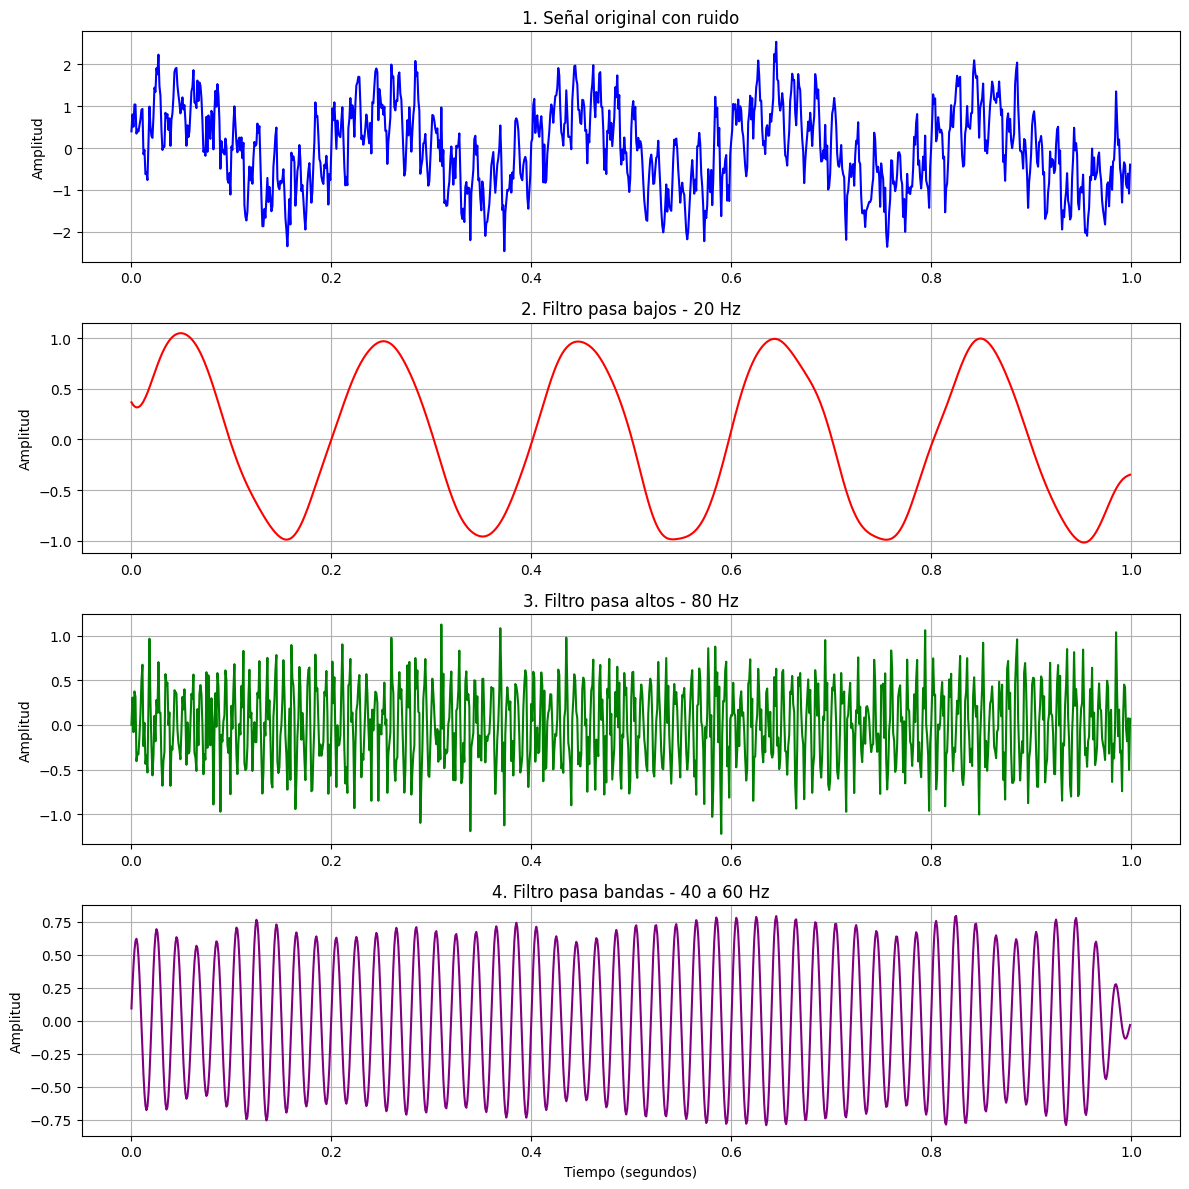

In [6]:

# PASO 8: COMPARACION DE LOS TRES FILTROS

# Crear una figura con cuatro graficas
fig, axs = plt.subplots(4, 1, figsize=(12, 12))

# Grafica 1: Señal original
axs[0].plot(t, senal, color="blue")
axs[0].set_title("1. Señal original con ruido")
axs[0].set_ylabel("Amplitud")
axs[0].grid(True)

# Grafica 2: Filtro pasa bajos
axs[1].plot(t, filtrada_bajos, color="red")
axs[1].set_title("2. Filtro pasa bajos - 20 Hz")
axs[1].set_ylabel("Amplitud")
axs[1].grid(True)

# Grafica 3: Filtro pasa altos
axs[2].plot(t, filtrada_altos, color="green")
axs[2].set_title("3. Filtro pasa altos - 80 Hz")
axs[2].set_ylabel("Amplitud")
axs[2].grid(True)

# Grafica 4: Filtro pasa bandas
axs[3].plot(t, filtrada_bandas, color="purple")
axs[3].set_title("4. Filtro pasa bandas - 40 a 60 Hz")
axs[3].set_ylabel("Amplitud")
axs[3].set_xlabel("Tiempo (segundos)")
axs[3].grid(True)

# Ajustar espacios
plt.tight_layout()

# Guardar imagen
plt.savefig("05_Comparacion_Filtros.png", dpi=300)

# Mostrar las graficas
plt.show()


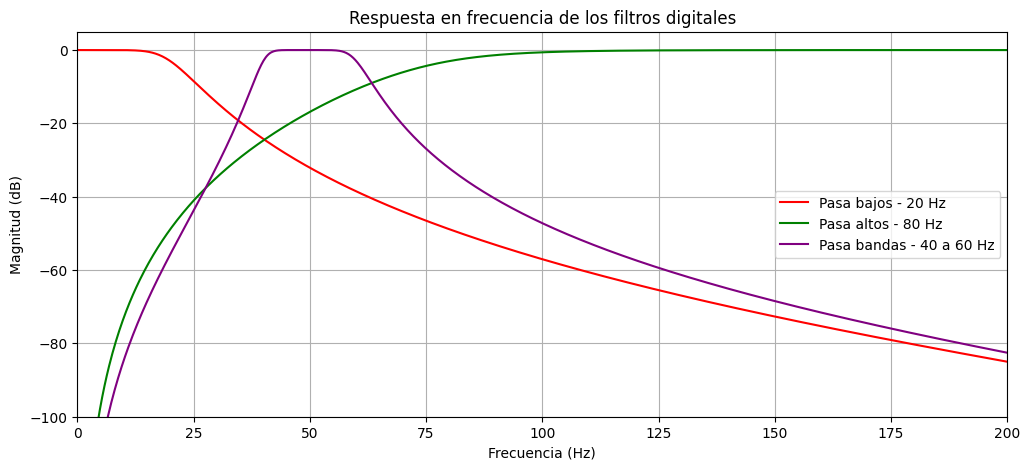

In [7]:

# PASO 9: ANALISIS DE RESPUESTA EN FRECUENCIA

# Crear una nueva figura
plt.figure(figsize=(12, 5))

# Definir los filtros a analizar
filtros = [
    (sos_bajos, "Pasa bajos - 20 Hz", "red"),
    (sos_altos, "Pasa altos - 80 Hz", "green"),
    (sos_bandas, "Pasa bandas - 40 a 60 Hz", "purple")
]

# Calcular la respuesta de cada filtro
for sos, nombre, color in filtros:

    frecuencias, respuesta = sosfreqz(
        sos, worN=2048, fs=fs
    )

    # Convertir magnitud a decibelios
    magnitud = 20 * np.log10(
        np.maximum(np.abs(respuesta), 1e-10)
    )

    # Graficar la respuesta
    plt.plot(frecuencias, magnitud,
             label=nombre, color=color)

# Configurar la grafica
plt.title("Respuesta en frecuencia de los filtros digitales")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud (dB)")
plt.xlim(0, 200)
plt.ylim(-100, 5)
plt.legend()
plt.grid(True)

# Guardar la grafica
plt.savefig("06_Respuesta_Frecuencia.png", dpi=300)

plt.show()


In [8]:

# PASO 10: EVALUAR LA EFECTIVIDAD DE LOS FILTROS

# Frecuencias que vamos a evaluar
frecuencias_evaluar = [5, 50, 120]

# Señales que vamos a comparar
senales = {
    "Original": senal,
    "Pasa bajos": filtrada_bajos,
    "Pasa altos": filtrada_altos,
    "Pasa bandas": filtrada_bandas
}

# Calcular amplitudes mediante transformada de Fourier
for nombre, datos in senales.items():

    espectro = np.fft.rfft(datos)
    frecuencias = np.fft.rfftfreq(len(datos), 1/fs)
    amplitudes = 2 * np.abs(espectro) / len(datos)

    print("\n", nombre)

    for f in frecuencias_evaluar:
        indice = np.argmin(np.abs(frecuencias - f))

        print(
            f"Frecuencia {f} Hz: "
            f"Amplitud {amplitudes[indice]:.4f}"
        )



 Original
Frecuencia 5 Hz: Amplitud 0.9980
Frecuencia 50 Hz: Amplitud 0.6991
Frecuencia 120 Hz: Amplitud 0.5081

 Pasa bajos
Frecuencia 5 Hz: Amplitud 0.9977
Frecuencia 50 Hz: Amplitud 0.0048
Frecuencia 120 Hz: Amplitud 0.0020

 Pasa altos
Frecuencia 5 Hz: Amplitud 0.0000
Frecuencia 50 Hz: Amplitud 0.0147
Frecuencia 120 Hz: Amplitud 0.4909

 Pasa bandas
Frecuencia 5 Hz: Amplitud 0.0035
Frecuencia 50 Hz: Amplitud 0.6851
Frecuencia 120 Hz: Amplitud 0.0006


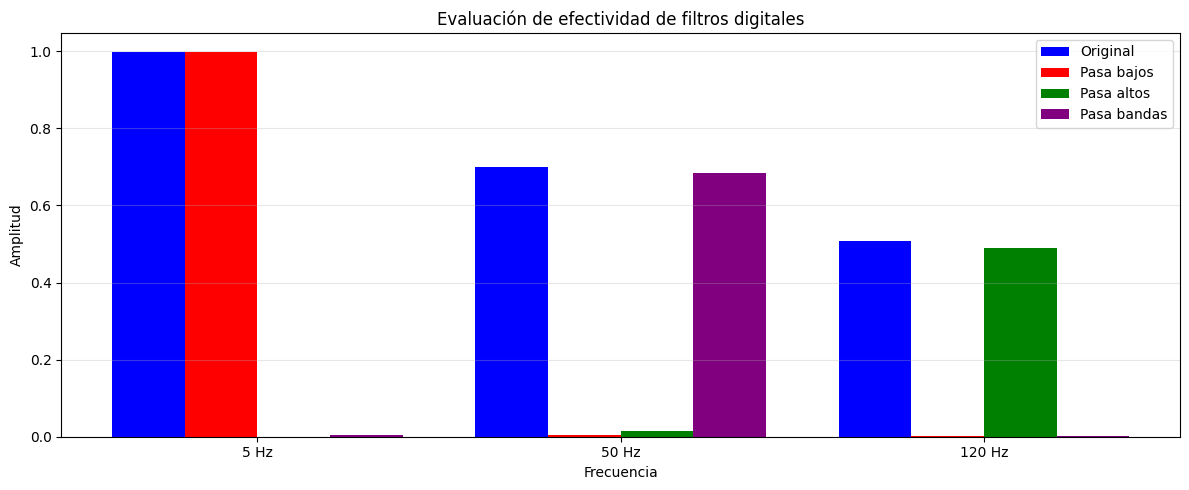

In [9]:

# PASO 11: GRAFICA DE EVALUACION DE FILTROS

# Frecuencias analizadas
frecuencias = [5, 50, 120]

# Calcular amplitudes de cada señal
def obtener_amplitudes(datos):
    espectro = np.fft.rfft(datos)
    freqs = np.fft.rfftfreq(len(datos), 1/fs)
    amplitudes = 2 * np.abs(espectro) / len(datos)

    return [
        amplitudes[np.argmin(np.abs(freqs - f))]
        for f in frecuencias
    ]

# Obtener valores
original = obtener_amplitudes(senal)
bajos = obtener_amplitudes(filtrada_bajos)
altos = obtener_amplitudes(filtrada_altos)
bandas = obtener_amplitudes(filtrada_bandas)

# Posiciones de las barras
x = np.arange(len(frecuencias))
ancho = 0.2

plt.figure(figsize=(12, 5))

plt.bar(x - 1.5*ancho, original, ancho,
        label="Original", color="blue")

plt.bar(x - 0.5*ancho, bajos, ancho,
        label="Pasa bajos", color="red")

plt.bar(x + 0.5*ancho, altos, ancho,
        label="Pasa altos", color="green")

plt.bar(x + 1.5*ancho, bandas, ancho,
        label="Pasa bandas", color="purple")

plt.xticks(x, ["5 Hz", "50 Hz", "120 Hz"])
plt.ylabel("Amplitud")
plt.xlabel("Frecuencia")
plt.title("Evaluación de efectividad de filtros digitales")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("07_Evaluacion_Filtros.png", dpi=300)
plt.show()
